# Incendios en el Perú — ¿cuánto y dónde se quemó en 2026?

En el Perú no hay una cifra de área quemada que se actualice cada semana para los 1 873
distritos. SERFOR e INDECI reportan emergencias, pero con rezago y sin un mapa homogéneo.
Entonces: ¿cómo sabemos dónde se está quemando el país, y cuánto?

Desde el espacio. Dos productos de la NASA miran el mismo fenómeno de forma distinta:

| Producto | Qué registra | Resolución | Frecuencia |
|---|---|---|---|
| **Área quemada** (MODIS MCD64A1) | el píxel que quedó quemado y el mes en que pasó | ~463 m | mensual, con 2–3 meses de rezago |
| **Focos de calor** (FIRMS, VIIRS) | un punto donde el satélite vio algo caliente al pasar | 375 m | varias veces al día |

En esta clase repetimos el flujo de `raster_aplicado.ipynb`, ahora con incendios:

| Paso | Qué hacemos |
|---|---|
| 1 | Preparar el raster de área quemada (2024, 2025 y 2026) |
| 2 | Limpiar los focos de calor: fuera volcanes y fuentes fijas |
| 3 | Cruzar el raster y los focos con los polígonos de distritos |
| 4 | Armar una presentación en HTML con los resultados |

## 0 · Preparación

Las dependencias están en el proyecto. Los datos se bajan una vez con los scripts de
`scripts/`:

```bash
uv sync --system-certs
uv run --system-certs python scripts/descargar_datos.py --anios 2021 2025    # focos anuales + distritos
uv run --system-certs python scripts/descargar_datos.py --nrt 7d             # focos de los últimos 7 días
uv run --system-certs python scripts/descargar_area_quemada.py --proyecto TU-PROYECTO --anios 2024 2025 2026
```

`--system-certs` hace falta en esta PC porque algo (antivirus o proxy) intercepta HTTPS. El
último script usa Google Earth Engine: la primera vez abre el navegador para iniciar sesión.

In [1]:
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

# 2026 en el color de acento; los años de referencia, apagados
COLOR = {2024: "#9aa7b0", 2025: "#5f7d8c", 2026: "#c1663f"}
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = RAIZ / "data" / "raw"
ANIOS = [2024, 2025, 2026]
QUEMADO = {a: RAW / "rasters" / f"area_quemada_{a}.tif" for a in ANIOS}
DISTRITOS = RAW / "distritos" / "DISTRITOS.shp"

faltan = [p.name for p in [*QUEMADO.values(), DISTRITOS] if not p.exists()]
assert not faltan, f"faltan archivos, corre los scripts de descarga: {faltan}"
print("datos listos en", RAW.relative_to(RAIZ))


def bonito(nombre: str) -> str:
    """'MADRE DE DIOS' -> 'Madre de Dios', para tablas y diapositivas."""
    menores = {"de", "del", "la", "las", "los", "el", "y"}
    palabras = nombre.lower().split()
    return " ".join(p if i and p in menores else p.capitalize() for i, p in enumerate(palabras))

datos listos en data\raw


## 1 · Preparar el raster

El raster lo bajó `descargar_area_quemada.py` desde Earth Engine, con el producto
MCD64A1. Cada píxel guarda **el mes en que se quemó por primera vez en el año**:
1 = enero … 12 = diciembre, y 0 = no se quemó. Abramos el de 2026.

In [2]:
with rasterio.open(QUEMADO[2026]) as src:
    mes_2026 = src.read(1)          # banda 1 -> np.ndarray 2D
    crs_raster = src.crs
    transform = src.transform
    limites = src.bounds
    res = src.res
    nodata = src.nodata

print(f"tipo         : {type(mes_2026).__name__}  {mes_2026.shape}   ({mes_2026.size:,} píxeles)")
print(f"dtype        : {mes_2026.dtype}")
print(f"CRS          : {crs_raster.to_dict()}")
print(f"resolución   : {res[0]:.1f} m por píxel")
print(f"extensión    : x [{limites.left / 1e3:,.0f}, {limites.right / 1e3:,.0f}] km   "
      f"y [{limites.bottom / 1e3:,.0f}, {limites.top / 1e3:,.0f}] km")
print(f"nodata       : {nodata}")

tipo         : ndarray  (4396, 3607)   (15,856,372 píxeles)
dtype        : uint8
CRS          : {'proj': 'sinu', 'lon_0': 0, 'x_0': 0, 'y_0': 0, 'R': 6371007.181, 'units': 'm', 'no_defs': True}
resolución   : 463.3 m por píxel
extensión    : x [-9,013, -7,342] km   y [-2,041, -4] km
nodata       : None


Tres diferencias con el raster de luces nocturnas:

- **El CRS no es EPSG:4326.** Es la proyección sinusoidal de MODIS (`proj: sinu`), en
  metros, no en grados.
- **Esa proyección es de igual área**: todos los píxeles miden lo mismo en el terreno.
  En la clase de luces hubo que proyectar a EPSG:24891 para medir áreas; aquí basta con
  contar píxeles.
- **No hay `nodata`.** El 0 no es un hueco: es un dato, «aquí no se quemó».

In [3]:
HA_PIXEL = abs(transform.a * transform.e) / 1e4      # m² -> hectáreas
print(f"cada píxel mide {res[0]:.0f} m × {res[1]:.0f} m = {HA_PIXEL:.2f} ha")

cada píxel mide 463 m × 463 m = 21.47 ha


### 1.1 · Mira los valores antes de graficar

In [4]:
valores, cuenta = np.unique(mes_2026, return_counts=True)
print(pd.Series(cuenta, index=valores, name="píxeles").rename_axis("mes").to_string())
print(f"\nquemados: {(mes_2026 > 0).sum():,} de {mes_2026.size:,}  ({(mes_2026 > 0).mean():.3%})")

mes
0    15853581
1           7
2          95
4         263
5         201
6         274
7         271
8        1680

quemados: 2,791 de 15,856,372  (0.018%)


Dos hallazgos:

**Faltan los meses 9 a 12.** MCD64A1 se publica con dos o tres meses de rezago: el
archivo de 2026 llega hasta agosto. Septiembre, el mes más fuerte de la temporada, todavía
no está.

**El rectángulo no es el Perú.** El archivo cubre el recuadro que encierra al país, y ese
recuadro trae Brasil, Bolivia, Ecuador, Colombia y el mar. Un píxel quemado en Pando no es
un incendio peruano. Hay que recortar.

In [5]:
from rasterio.mask import mask

distritos = gpd.read_file(DISTRITOS)
peru_4326 = distritos.dissolve()                       # los 1 873 distritos -> un polígono
peru = peru_4326.to_crs(crs_raster).geometry           # en el CRS del raster


def leer_en_peru(ruta):
    """Lee el raster y enmascara lo que cae fuera del Perú."""
    with rasterio.open(ruta) as src:
        banda, _ = mask(src, peru, crop=False, filled=False)   # filled=False -> masked array
    return banda[0]


mes = {a: leer_en_peru(QUEMADO[a]) for a in ANIOS}

filas = []
for a in ANIOS:
    with rasterio.open(QUEMADO[a]) as src:
        en_rectangulo = int((src.read(1) > 0).sum())
    en_peru = int((mes[a] > 0).sum())                  # los píxeles enmascarados no cuentan
    filas.append({"año": a, "quemados en el rectángulo": en_rectangulo, "quemados en el Perú": en_peru,
                  "% de afuera": 1 - en_peru / en_rectangulo, "ha en el Perú": en_peru * HA_PIXEL})
recorte = pd.DataFrame(filas).set_index("año")
recorte.style.format({"quemados en el rectángulo": "{:,}", "quemados en el Perú": "{:,}",
                      "% de afuera": "{:.0%}", "ha en el Perú": "{:,.0f}"})

,quemados en el rectángulo,quemados en el Perú,% de afuera,ha en el Perú
año,,,,
2024,"36,534","14,009",62%,"300,715"
2025,"5,530","2,478",55%,"53,192"
2026,"2,791","1,910",32%,"41,000"


En 2024, **más de la mitad de lo quemado en el rectángulo estaba fuera del Perú**: fue el
año de los grandes incendios de Bolivia y Brasil. Sin recortar, le habríamos atribuido al
Perú los incendios de sus vecinos.

Para verlo en un mapa hay un problema de escala: un píxel de 463 m es invisible en un
mapa nacional. Agrupamos los píxeles en bloques de 10 × 10 (~4.6 km) y sumamos las
hectáreas de cada bloque.

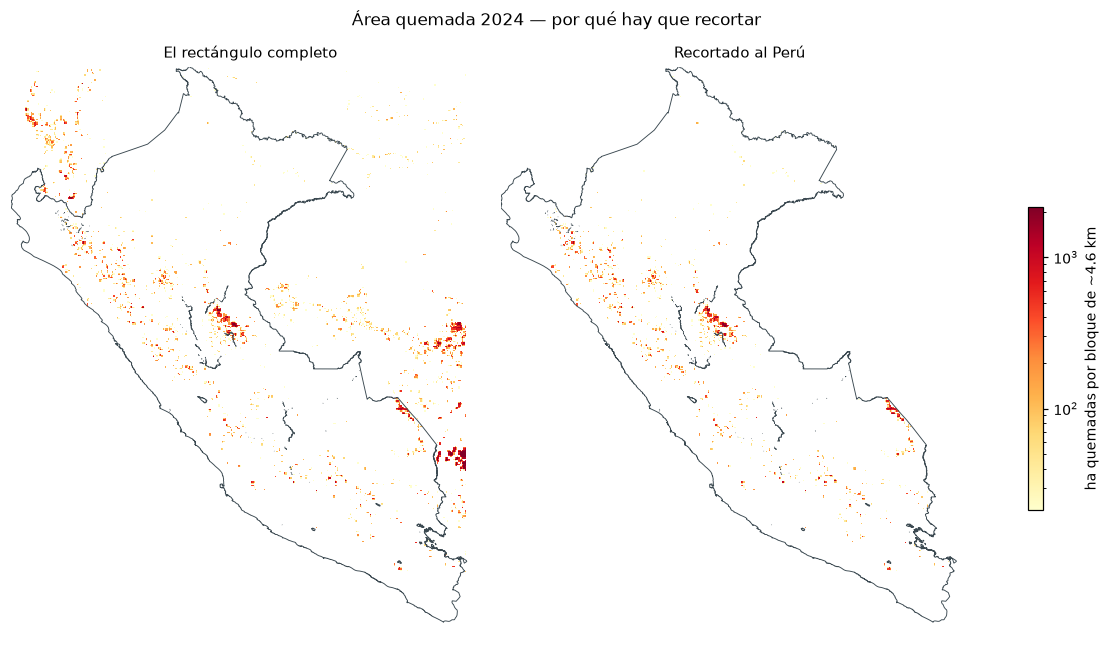

In [6]:
from matplotlib.colors import LogNorm

K = 10                                                   # 10 píxeles -> bloques de ~4.6 km


def a_bloques(quemado, k=K):
    """Suma las hectáreas quemadas en bloques de k × k píxeles."""
    f, c = (quemado.shape[0] // k) * k, (quemado.shape[1] // k) * k
    return quemado[:f, :c].reshape(f // k, k, c // k, k).sum(axis=(1, 3)) * HA_PIXEL


with rasterio.open(QUEMADO[2024]) as src:
    bloques_rect = a_bloques(src.read(1) > 0)
bloques_peru = a_bloques(np.ma.filled(mes[2024], 0) > 0)

filas_b, cols_b = bloques_rect.shape
extension = (limites.left, limites.left + cols_b * K * res[0], limites.top - filas_b * K * res[1], limites.top)

fig_recorte, (izq, der) = plt.subplots(1, 2, figsize=(10, 6), layout="constrained")
norma = LogNorm(vmin=HA_PIXEL, vmax=bloques_rect.max())
for ax, bloques, titulo in [(izq, bloques_rect, "El rectángulo completo"), (der, bloques_peru, "Recortado al Perú")]:
    imagen = ax.imshow(np.where(bloques > 0, bloques, np.nan), cmap="YlOrRd", norm=norma,
                       extent=extension, interpolation="nearest")
    peru.boundary.plot(ax=ax, color="#3c4a52", linewidth=0.6)
    ax.set_title(titulo, fontsize=9.5)
    ax.axis("off")
fig_recorte.colorbar(imagen, ax=[izq, der], shrink=0.5, label="ha quemadas por bloque de ~4.6 km")
fig_recorte.suptitle("Área quemada 2024 — por qué hay que recortar", fontsize=11)
plt.show()

### 1.2 · ¿En qué meses se quema?

Con el raster recortado, contar píxeles por valor da las hectáreas de cada mes.

In [7]:
por_mes = pd.DataFrame({
    a: pd.Series(np.ma.compressed(mes[a][mes[a] > 0])).value_counts().reindex(range(1, 13), fill_value=0) * HA_PIXEL
    for a in ANIOS
})
por_mes.loc[9:, 2026] = np.nan          # todavía no publicados: no es lo mismo que 0
por_mes.index = MESES
por_mes.round(0)

,2024,2025,2026
ene,43.00,86.00,129.00
feb,0.00,0.00,"2,039.00"
mar,64.00,0.00,0.00
abr,623.00,193.00,"4,851.00"
may,"1,996.00","4,014.00","3,177.00"
jun,"3,606.00","2,168.00","4,186.00"
jul,"9,617.00","8,007.00","2,683.00"
ago,"67,381.00","5,925.00","23,934.00"
sep,"174,539.00","14,532.00",NaN
oct,"29,666.00","2,490.00",NaN


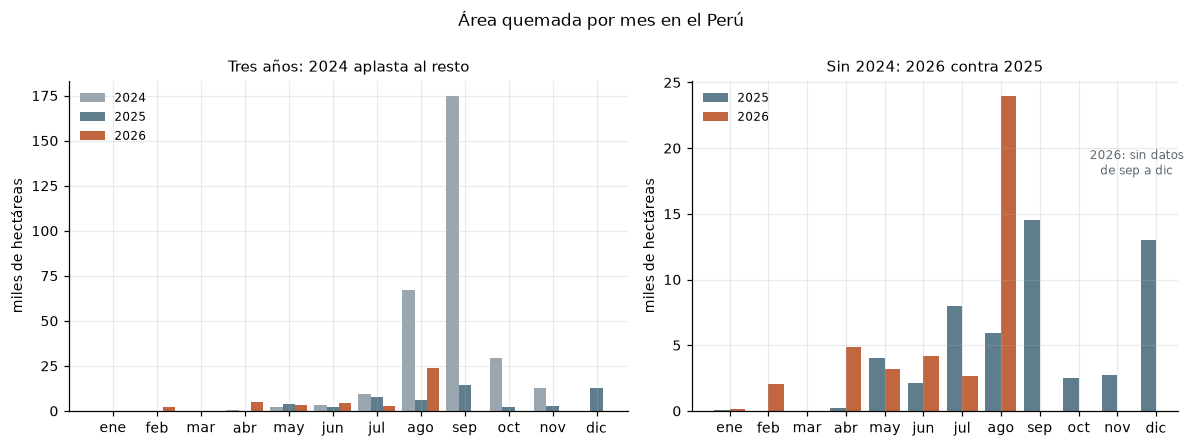

In [8]:
fig_mes, (izq, der) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.15, 1]})
x = np.arange(12)

ancho = 0.28
for k, a in enumerate(ANIOS):
    izq.bar(x + (k - 1) * ancho, por_mes[a] / 1e3, width=ancho, color=COLOR[a], label=str(a))
izq.set_title("Tres años: 2024 aplasta al resto", fontsize=9.5)

ancho = 0.4
for k, a in enumerate([2025, 2026]):
    der.bar(x + (k - 0.5) * ancho, por_mes[a] / 1e3, width=ancho, color=COLOR[a], label=str(a))
der.set_title("Sin 2024: 2026 contra 2025", fontsize=9.5)
der.annotate("2026: sin datos\nde sep a dic", xy=(10.5, 18), ha="center", fontsize=8, color="#5f6b73")

for ax in (izq, der):
    ax.set_xticks(x, MESES)
    ax.set_ylabel("miles de hectáreas")
    ax.legend(frameon=False, fontsize=8)
fig_mes.suptitle("Área quemada por mes en el Perú", fontsize=11, y=1.0)
plt.tight_layout()
plt.show()

La temporada va de **julio a octubre** y tiene su pico en septiembre, cuando la vegetación
está más seca. Pero los años no se parecen:

- **2024 fue extraordinario**: solo septiembre suma más de 170 000 ha.
- **2026 va por encima de 2025**: agosto de 2026 cuadruplica a agosto de 2025, y todavía
  faltan septiembre y octubre.

Mismo dato, dos escalas, como en la clase de luces: con 2024 en el gráfico, los otros dos
años casi no se ven.

## 2 · Limpiar los focos de calor: fuera volcanes y fuentes fijas

El área quemada solo ve quemas grandes, y con meses de rezago. Para saber qué pasa **esta
semana** están los focos de calor. Pero un foco no es siempre un incendio: el satélite
detecta *cualquier cosa caliente*. En el archivo anual, FIRMS clasifica cada foco en la
columna `type`:

| `type` | Qué es |
|---|---|
| 0 | presunto incendio de vegetación |
| 1 | volcán activo |
| 2 | otra fuente fija en tierra: industria, mecheros de gas |
| 3 | costa afuera |

In [9]:
FOCOS_2025 = RAW / "firms" / "viirs-snpp_2025_Peru.csv"

crudos = pd.read_csv(FOCOS_2025, parse_dates=["acq_date"])
crudos = gpd.GeoDataFrame(crudos, geometry=gpd.points_from_xy(crudos.longitude, crudos.latitude),
                          crs="EPSG:4326")

print(f"{len(crudos):,} focos en 2025\n")
print(crudos["type"].value_counts().sort_index()
      .rename({0: "0 vegetación", 1: "1 volcán", 2: "2 fuente fija", 3: "3 costa afuera"}).to_string())

53,579 focos en 2025

type
0 vegetación      51742
1 volcán              5
2 fuente fija      1602
3 costa afuera      230


> **Ojo:** en un GeoDataFrame, `crudos.type` **no** es la columna: es el tipo de geometría
> de cada fila (`Point`). Filtrar con `crudos.type == 2` devuelve cero filas sin avisar.
> Usa siempre `crudos["type"]`.

¿Dónde están los focos que no son vegetación? Si la clasificación es buena, deberían caer
en lugares que conocemos.

In [10]:
con_distrito = gpd.sjoin(crudos, distritos[["DEPARTAMEN", "PROVINCIA", "DISTRITO", "geometry"]],
                         how="left", predicate="within")
con_distrito[["DISTRITO", "PROVINCIA"]] = con_distrito[["DISTRITO", "PROVINCIA"]].fillna("(en el mar)")

for t, nombre in [(1, "volcán"), (2, "fuente fija"), (3, "costa afuera")]:
    sub = con_distrito[con_distrito["type"] == t]
    print(f"type {t} · {nombre}: {len(sub)} focos")
    print(sub.groupby(["DISTRITO", "PROVINCIA"]).size().nlargest(6).to_string(), "\n")

type 1 · volcán: 5 focos
DISTRITO  PROVINCIA
LLUTA     CAYLLOMA     4
MACA      CAYLLOMA     1 

type 2 · fuente fija: 1602 focos
DISTRITO   PROVINCIA    
PARACAS    PISCO            582
PACOCHA    ILO              451
MEGANTONI  LA CONVENCION    182
CHIMBOTE   SANTA            106
PARIÑAS    TALARA            93
ANTIOQUIA  HUAROCHIRI        52 

type 3 · costa afuera: 230 focos
DISTRITO      PROVINCIA  
(en el mar)   (en el mar)    79
PARIÑAS       TALARA         64
PACOCHA       ILO            12
LAS AMAZONAS  MAYNAS         11
BELLA UNION   CARAVELI        9
LOMAS         CARAVELI        9 



Igual que con las minas en la clase de luces: el algoritmo no sabe nada del Perú y aun así
encuentra lugares conocidos.

| Distrito | Qué hay ahí |
|---|---|
| Paracas (Pisco) | planta de procesamiento del gas de Camisea |
| Pacocha (Ilo) | complejo metalúrgico de Ilo |
| Megantoni (La Convención) | planta de gas de Malvinas (Camisea) |
| Chimbote (Santa) | siderúrgica |
| Pariñas (Talara) | refinería y mecheros petroleros, también en el mar |
| Lluta y Maca (Caylloma) | volcán Sabancaya |

Si el ranking hubiera devuelto distritos amazónicos, sabríamos que algo está mal.

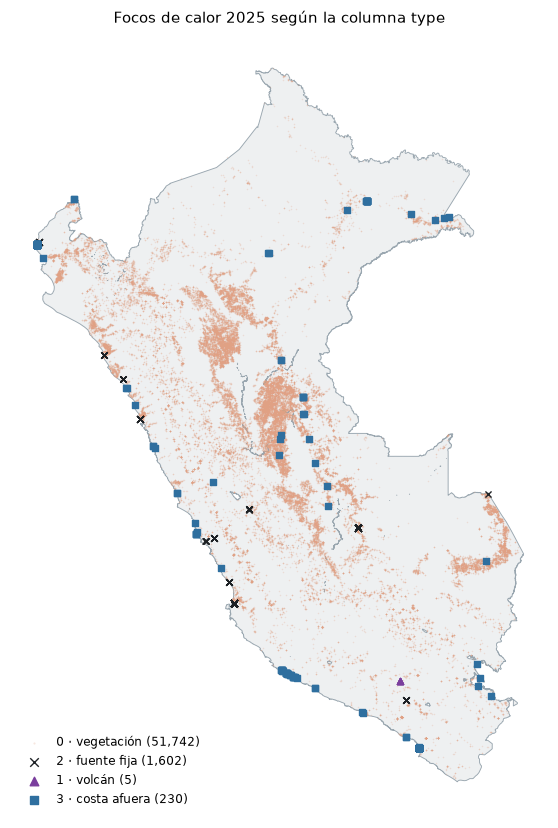

In [11]:
fig_tipos, ax = plt.subplots(figsize=(6.4, 7.6))
peru_4326.plot(ax=ax, color="#eef0f1", edgecolor="#9aa7b0", linewidth=0.6)

veg = crudos[crudos["type"] == 0]
ax.scatter(veg.longitude, veg.latitude, s=1, c="#e0a184", alpha=0.25, linewidths=0,
           label=f"0 · vegetación ({len(veg):,})")
for t, color, marca, nombre in [(2, "#1d2125", "x", "fuente fija"), (1, "#7a3e9d", "^", "volcán"),
                                (3, "#2f6f9f", "s", "costa afuera")]:
    sub = crudos[crudos["type"] == t]
    ax.scatter(sub.longitude, sub.latitude, s=16, c=color, marker=marca, linewidths=0.9,
               label=f"{t} · {nombre} ({len(sub):,})")

ax.legend(frameon=False, fontsize=8, loc="lower left", markerscale=1.4)
ax.set_title("Focos de calor 2025 según la columna type", fontsize=10)
ax.axis("off")
plt.tight_layout()
plt.show()

Quedarse con `type == 0` y sacar la confianza baja es lo que hace `leer_focos` en
`src/focos/firms.py`:

In [12]:
from focos import leer_focos

focos_2025 = leer_focos(FOCOS_2025)          # type == 0 y sin confianza baja
no_vegetacion = (crudos["type"] != 0).sum()
print(f"crudos              : {len(crudos):>7,}")
print(f"  no vegetación     : {no_vegetacion:>7,}")
print(f"  confianza baja    : {len(crudos) - no_vegetacion - len(focos_2025):>7,}")
print(f"limpios             : {len(focos_2025):>7,}")

crudos              :  53,579
  no vegetación     :   1,837
  confianza baja    :   2,736
limpios             :  49,006


### 2.1 · El problema: los focos de esta semana no traen `type`

FIRMS asigna `type` recién cuando procesa el archivo anual. Los focos en tiempo casi real
(NRT), los únicos que muestran lo que pasa esta semana, vienen **sin esa columna**.

La salida: **usar el pasado para limpiar el presente**. Una fuente fija no se mueve. Si un
lugar fue volcán o industria en 2021 o en 2025, lo sigue siendo hoy. Sacamos los focos de
esta semana que caen a menos de 1 km de alguno de esos lugares. El kilómetro cubre el
píxel de VIIRS (375 m) más el error de posición entre una pasada y otra.

In [13]:
NRT = sorted((RAW / "firms").glob("viirs-snpp_nrt_7d_*_Peru.csv"))[-1]
semana = leer_focos(NRT)                      # sin `type`: solo saca la confianza baja
print(f"archivo: {NRT.name}")
print(f"{len(semana):,} focos del {semana.acq_date.min():%d/%m} al {semana.acq_date.max():%d/%m}"
      f"   ¿trae `type`? {'type' in semana.columns}")

anuales = [RAW / "firms" / f"viirs-snpp_{a}_Peru.csv" for a in (2021, 2025)]
fijos = pd.concat([pd.read_csv(p) for p in anuales if p.exists()])
fijos = fijos[fijos["type"] != 0]
fijos = gpd.GeoDataFrame(fijos, geometry=gpd.points_from_xy(fijos.longitude, fijos.latitude), crs="EPSG:4326")
print(f"focos de referencia (volcán, industria, mar): {len(fijos):,}")

# distancias en metros: EPSG:24891, el CRS métrico de la clase de luces
cercanos = gpd.sjoin_nearest(semana.to_crs(epsg=24891), fijos[["geometry"]].to_crs(epsg=24891),
                             max_distance=1000, how="left")
es_fijo = cercanos["index_right"].notna().groupby(level=0).any().reindex(semana.index).values
semana_limpia = semana[~es_fijo]
print(f"a menos de 1 km de una fuente fija: {es_fijo.sum()}  ->  quedan {len(semana_limpia):,}")

archivo: viirs-snpp_nrt_7d_2026-10-21_Peru.csv
3,171 focos del 14/10 al 21/10   ¿trae `type`? False


focos de referencia (volcán, industria, mar): 3,797
a menos de 1 km de una fuente fija: 34  ->  quedan 3,137


In [14]:
quitados = gpd.sjoin(semana[es_fijo], distritos[["DISTRITO", "PROVINCIA", "geometry"]], how="left", predicate="within")
quitados.groupby(["DISTRITO", "PROVINCIA"]).size().sort_values(ascending=False).head(8)

DISTRITO               PROVINCIA
PARACAS                PISCO        17
PACOCHA                ILO           5
CHIMBOTE               SANTA         3
HUANCHACO              TRUJILLO      3
LA UNION               TARMA         3
PACASMAYO              PACASMAYO     1
SAN VICENTE DE CAÑETE  CAÑETE        1
YURA                   AREQUIPA      1
dtype: int64

Los focos que salieron caen en Paracas, Pacocha, Chimbote y otros lugares de la lista
industrial de arriba: el método saca lo que tiene que sacar. Son pocos porque esta semana
la señal es otra. Casi todo lo que el satélite ve es quema de vegetación.

## 3 · Cruzar con los polígonos de distritos

Tenemos un raster recortado y focos limpios. Ahora, como en la clase de luces, **una fila
por distrito**. Primero el chequeo obligatorio de CRS:

In [15]:
print("distritos:", distritos.crs.to_string(), "   raster:", crs_raster.to_dict()["proj"])
assert distritos.crs != crs_raster
distritos_sinu = distritos.to_crs(crs_raster)
print("polígonos reproyectados al CRS del raster")

distritos: EPSG:4326    raster: sinu


polígonos reproyectados al CRS del raster


Esta vez **no coinciden**, y se reproyectan los polígonos, no el raster. Reproyectar un
raster obliga a remuestrear los píxeles y cambia cuánto mide cada uno. Reproyectar un
polígono solo mueve sus vértices.

In [16]:
from rasterstats import zonal_stats

stats_2026 = zonal_stats(
    distritos_sinu,            # los polígonos, ya en el CRS del raster
    str(QUEMADO[2026]),        # el raster
    categorical=True,          # en vez de mean/sum: cuántos píxeles hay de cada valor (= de cada mes)
    nodata=0,                  # el 0 («no se quemó») no lo queremos contar
    all_touched=False,         # cada píxel cuenta en UN solo distrito
)

ha_2026 = pd.DataFrame(stats_2026, index=distritos.index).fillna(0) * HA_PIXEL
ha_2026 = ha_2026.reindex(columns=range(1, 13), fill_value=0)
print(f"{len(ha_2026)} filas — una por distrito; una columna por mes")
stats_2026[:3]

1873 filas — una por distrito; una columna por mes


[{}, {8: 14}, {}]

Tres argumentos que deciden si el resultado es correcto:

| Argumento | Por qué importa |
|---|---|
| `categorical=True` | el valor del píxel es una categoría (el mes), no una cantidad: promediarlo no tiene sentido |
| `nodata=0` | el 0 sí es un dato, pero no queremos contarlo; declararlo como `nodata` lo saca del conteo |
| `all_touched=False` | **al revés que en la clase de luces.** Para contar área, un píxel en el borde de dos distritos se contaría dos veces |

Lo mismo, empaquetado, es `area_quemada_por_distrito` en `src/focos/cruce.py`. La usamos
para los tres años:

In [17]:
from focos import area_quemada_por_distrito

ha = {a: area_quemada_por_distrito(distritos, QUEMADO[a]) for a in ANIOS}
assert np.allclose(ha[2026], ha_2026)

panel = distritos[["DEPARTAMEN", "PROVINCIA", "DISTRITO", "geometry"]].copy()
for a in ANIOS:
    panel[f"ha_{a}"] = ha[a].sum(axis=1)
ultimo_mes = int(np.ma.max(mes[2026]))           # último mes publicado de 2026
for a in ANIOS:
    panel[f"ha_{a}_mismo_periodo"] = ha[a].loc[:, 1:ultimo_mes].sum(axis=1)

print(f"panel: {panel.shape[0]:,} distritos · 2026 llega hasta {MESES[ultimo_mes - 1]}")
print(f"distritos con algo quemado: " + ", ".join(f"{a}: {(panel[f'ha_{a}'] > 0).sum()}" for a in ANIOS))

panel: 1,873 distritos · 2026 llega hasta ago
distritos con algo quemado: 2024: 481, 2025: 197, 2026: 138


### 3.1 · Validar antes de creer

Primera validación, la más barata: la suma de los distritos tiene que dar el total del
raster recortado.

In [18]:
for a in ANIOS:
    print(f"{a}: suma de distritos {panel[f'ha_{a}'].sum():>9,.0f} ha   "
          f"raster recortado {recorte.loc[a, 'ha en el Perú']:>9,.0f} ha")

2024: suma de distritos   300,715 ha   raster recortado   300,715 ha
2025: suma de distritos    53,192 ha   raster recortado    53,192 ha
2026: suma de distritos    41,000 ha   raster recortado    41,000 ha


Cuadra exacto, y no es casualidad: el recorte con `mask` y `zonal_stats` con
`all_touched=False` usan la misma regla. Un píxel pertenece al polígono que contiene su
centro, así que cada píxel cae en un solo distrito y ninguno se pierde ni se duplica.

Segunda validación: ¿los distritos de arriba tienen sentido?

In [19]:
def top(a, n=8):
    t = panel.nlargest(n, f"ha_{a}")
    return (t.DISTRITO.map(bonito) + " (" + t.DEPARTAMEN.map(bonito) + ")  "
            + t[f"ha_{a}"].map("{:,.0f}".format)).values

ranking = pd.DataFrame({str(a): top(a) for a in ANIOS}, index=range(1, 9))
ranking

,2024,2025,2026
1,"Iberia (Madre de Dios) 24,772","Las Piedras (Madre de Dios) 2,962","Acora (Puno) 2,898"
2,"Nueva Requena (Ucayali) 23,698","Sitacocha (Cajamarca) 2,125","Puno (Puno) 2,662"
3,"Manantay (Ucayali) 21,423","Ignacio Escudero (Piura) 1,975","Pacanga (La Libertad) 2,426"
4,"Campoverde (Ucayali) 10,754","Huasta (Ancash) 1,588","Ignacio Escudero (Piura) 2,082"
5,"Tahuamanu (Madre de Dios) 9,402","Yanacancha (Junin) 1,546","Lambayeque (Lambayeque) 1,889"
6,"Masisea (Ucayali) 9,295","La Huaca (Piura) 1,503","Junin (Junin) 1,266"
7,"Honoria (Huanuco) 8,350","Pacanga (La Libertad) 1,202","Campoverde (Ucayali) 1,245"
8,"Yarinacocha (Ucayali) 7,298","Allauca (Lima) 1,116",Tiquillaca (Puno) 987


- **2024**: Iberia y Tahuamanu (Madre de Dios), Nueva Requena, Manantay y Campoverde
  (Ucayali). Son los incendios de septiembre de 2024 en la Amazonía, que llevaron a
  declarar emergencia en varias regiones. La medida captura un evento real.
- **2026**: arriba aparecen Ácora y Puno, en el altiplano, donde se queman pajonales. Le
  siguen distritos de valles agrícolas de la costa norte: Pacanga, Ignacio Escudero,
  Lambayeque. Ahí lo más probable es la quema de caña o rastrojos.

> **Regla práctica:** área quemada no es lo mismo que incendio forestal. El satélite ve
> fuego en bosques, pajonales y cultivos por igual. Para separar habría que cruzar con un
> mapa de cobertura del suelo (ejercicio 1).

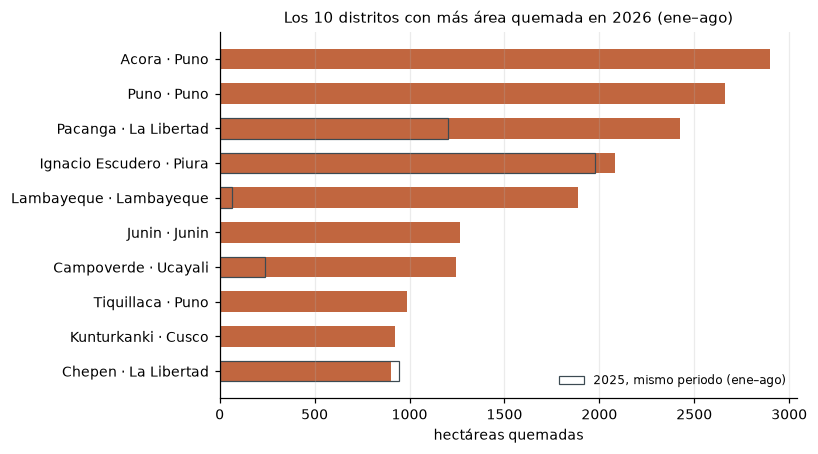

In [20]:
top_2026 = panel.nlargest(10, "ha_2026").iloc[::-1]
etiquetas = top_2026.DISTRITO.map(bonito) + " · " + top_2026.DEPARTAMEN.map(bonito)

fig_top, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(etiquetas, top_2026.ha_2026, color=COLOR[2026], height=0.6)
ax.barh(etiquetas, top_2026.ha_2025_mismo_periodo, color="none", edgecolor="#3c4a52",
        height=0.6, linewidth=0.8, label=f"2025, mismo periodo (ene–{MESES[ultimo_mes - 1]})")
ax.set_xlabel("hectáreas quemadas")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title(f"Los 10 distritos con más área quemada en 2026 (ene–{MESES[ultimo_mes - 1]})", fontsize=10)
plt.tight_layout()
plt.show()

### 3.2 · Segundo cruce: focos de calor por distrito

Los focos son puntos: el cruce con polígonos es un *spatial join*, no zonal statistics.
`focos_por_distrito` cuenta cuántos caen en cada distrito.

In [21]:
from focos import focos_por_distrito, valor_en_focos

panel["focos_2025"] = focos_por_distrito(focos_2025, distritos)["n_focos"]
panel["focos_semana"] = focos_por_distrito(semana_limpia, distritos)["n_focos"]

con_algo = panel[(panel.focos_2025 > 0) | (panel.ha_2025 > 0)]
r = np.corrcoef(np.log1p(con_algo.focos_2025), np.log1p(con_algo.ha_2025))[0, 1]
print(f"correlación entre log(focos) y log(ha quemadas), 2025: {r:.2f}  ({len(con_algo)} distritos)")

correlación entre log(focos) y log(ha quemadas), 2025: 0.34  (1401 distritos)


¿Los dos satélites ven lo mismo? Se puede medir en dos direcciones. Para el cruce
punto-raster usamos `valor_en_focos`, que lee el valor del píxel donde cae cada foco:

In [22]:
en_quemado = valor_en_focos(focos_2025, QUEMADO[2025]) > 0
print(f"focos de 2025 que caen sobre un píxel quemado      : {en_quemado.mean():.1%}")

# al revés: ¿cuántos píxeles quemados tienen un foco cerca? (los tres rasters comparten la misma malla)
fil, col = np.nonzero(np.ma.filled(mes[2025], 0) > 0)
xs, ys = rasterio.transform.xy(transform, fil, col)
pixeles = gpd.GeoDataFrame(geometry=gpd.points_from_xy(xs, ys), crs=crs_raster).to_crs(epsg=24891)
cerca = gpd.sjoin_nearest(pixeles, focos_2025[["geometry"]].to_crs(epsg=24891), max_distance=1000, how="left")
con_foco = cerca["index_right"].notna().groupby(level=0).any()
print(f"píxeles quemados de 2025 con un foco a menos de 1 km: {con_foco.mean():.1%}")

focos de 2025 que caen sobre un píxel quemado      : 1.4%


píxeles quemados de 2025 con un foco a menos de 1 km: 65.7%


La asimetría es la lección:

- **Dos de cada tres píxeles quemados tienen un foco al lado.** Las quemas grandes, los
  focos las ven. Esto también confirma que raster y puntos están bien alineados. Si el
  raster estuviera corrido, esta cifra se desplomaría.
- **Casi ningún foco cae sobre un píxel quemado.** La mayoría son quemas chicas: chacras,
  rastrojos, desbroce para cultivar. Ocupan menos de las 21 ha de un píxel de MODIS y el
  área quemada no las registra.

Cada producto mide algo distinto: el área quemada mide **cuánto**, los focos miden
**dónde y cuándo**. Por eso usamos los dos.

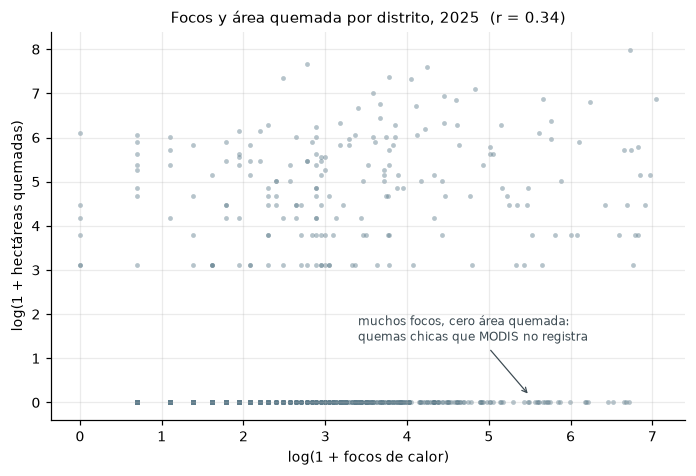

In [23]:
fig_dispersion, ax = plt.subplots(figsize=(6.4, 4.4))
ax.scatter(np.log1p(con_algo.focos_2025), np.log1p(con_algo.ha_2025), s=10, alpha=0.45,
           c="#5f7d8c", linewidths=0)
ax.set_xlabel("log(1 + focos de calor)")
ax.set_ylabel("log(1 + hectáreas quemadas)")
ax.set_title(f"Focos y área quemada por distrito, 2025  (r = {r:.2f})", fontsize=10)
ax.annotate("muchos focos, cero área quemada:\nquemas chicas que MODIS no registra",
            xy=(5.5, 0.15), xytext=(3.4, 1.4), fontsize=8, color="#3c4a52",
            arrowprops={"arrowstyle": "->", "color": "#3c4a52", "linewidth": 0.8})
plt.tight_layout()
plt.show()

### 3.3 · El mapa del resultado

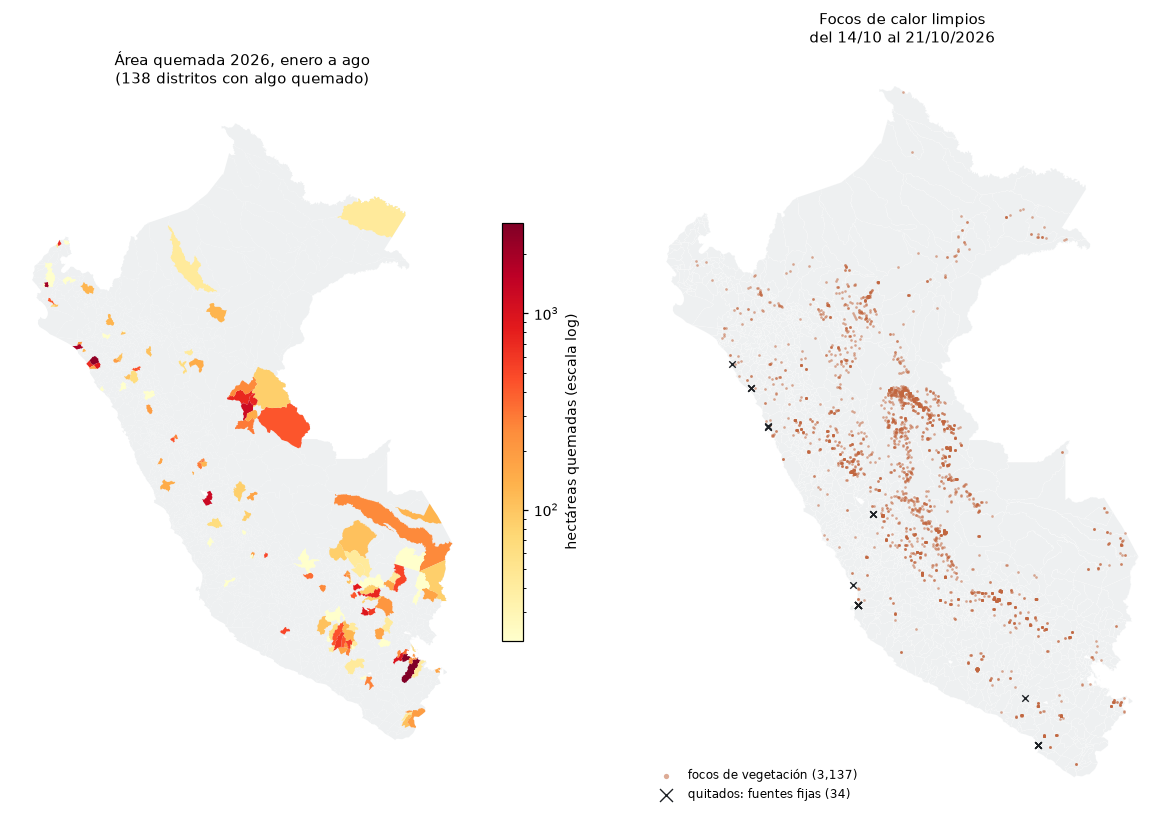

In [24]:
ini, fin = semana_limpia.acq_date.min(), semana_limpia.acq_date.max()

fig_mapa, (izq, der) = plt.subplots(1, 2, figsize=(11, 7.5))

panel.plot(color="#eef0f1", ax=izq, linewidth=0)
quemaron = panel[panel.ha_2026 > 0]
quemaron.plot(column="ha_2026", cmap="YlOrRd", norm=LogNorm(vmin=HA_PIXEL, vmax=quemaron.ha_2026.max()),
              ax=izq, linewidth=0, legend=True,
              legend_kwds={"label": "hectáreas quemadas (escala log)", "shrink": 0.55})
izq.set_title(f"Área quemada 2026, enero a {MESES[ultimo_mes - 1]}\n"
              f"({len(quemaron)} distritos con algo quemado)", fontsize=10)

panel.plot(color="#eef0f1", ax=der, edgecolor="white", linewidth=0.1)
der.scatter(semana_limpia.longitude, semana_limpia.latitude, s=3, c=COLOR[2026], alpha=0.55,
            linewidths=0, label=f"focos de vegetación ({len(semana_limpia):,})")
der.scatter(semana[es_fijo].longitude, semana[es_fijo].latitude, s=18, c="#1d2125", marker="x",
            linewidths=0.9, label=f"quitados: fuentes fijas ({es_fijo.sum()})")
der.legend(frameon=False, fontsize=8, loc="lower left", markerscale=2)
der.set_title(f"Focos de calor limpios\ndel {ini:%d/%m} al {fin:%d/%m/%Y}", fontsize=10)

for ax in (izq, der):
    ax.axis("off")
plt.tight_layout()
plt.show()

### 3.4 · ¿2026 es un año malo?

La comparación justa es contra el **mismo periodo** de los años anteriores, porque a 2026
le faltan los últimos meses.

In [25]:
mismo_periodo = pd.Series({a: panel[f"ha_{a}_mismo_periodo"].sum() for a in ANIOS})
print(f"área quemada ene–{MESES[ultimo_mes - 1]}:")
for a in ANIOS:
    print(f"  {a}: {mismo_periodo[a]:>8,.0f} ha")
print(f"2026 frente a 2025: ×{mismo_periodo[2026] / mismo_periodo[2025]:.1f}   "
      f"frente a 2024: ×{mismo_periodo[2026] / mismo_periodo[2024]:.1f}")

# la semana de los focos NRT contra las mismas fechas de 2025
hace_un_anio = focos_2025[focos_2025.acq_date.between(ini - pd.DateOffset(years=1), fin - pd.DateOffset(years=1))]
focos_semana_2025 = focos_por_distrito(hace_un_anio, distritos)["n_focos"].sum()
print(f"\nfocos del {ini:%d/%m} al {fin:%d/%m}: 2026 = {panel.focos_semana.sum():,}   "
      f"2025 = {focos_semana_2025:,}   (×{panel.focos_semana.sum() / focos_semana_2025:.1f})")

área quemada ene–ago:
  2024:   83,330 ha
  2025:   20,393 ha
  2026:   41,000 ha
2026 frente a 2025: ×2.0   frente a 2024: ×0.5



focos del 14/10 al 21/10: 2026 = 3,137   2025 = 814   (×3.9)


In [26]:
por_depto = (panel.groupby("DEPARTAMEN")[["ha_2024_mismo_periodo", "ha_2025_mismo_periodo", "ha_2026", "focos_semana"]]
             .sum().sort_values("ha_2026", ascending=False).head(10))
por_depto.index = por_depto.index.map(bonito)
por_depto.columns = ["ha 2024 (mismo periodo)", "ha 2025 (mismo periodo)", "ha 2026", "focos esta semana"]
por_depto.style.format("{:,.0f}")

,ha 2024 (mismo periodo),ha 2025 (mismo periodo),ha 2026,focos esta semana
DEPARTAMEN,,,,
Puno,"1,653","2,297","9,359",65
Cusco,"7,191","2,662","4,808",222
La Libertad,"3,048","4,100","4,358",40
Arequipa,"1,266",0,"3,284",121
Ucayali,"11,420","1,567","3,241",790
Piura,322,"3,070","2,855",7
Lambayeque,"1,717",429,"2,232",9
Junin,"7,899",64,"1,674",385
Huanuco,"7,685",64,"1,503",329


Dos señales que apuntan al mismo lado:

- **Área quemada:** de enero a agosto de 2026 se quemó el doble que en el mismo periodo
  de 2025, pero menos de la mitad que en 2024.
- **Focos de esta semana:** casi cuatro veces los de la misma semana de 2025, concentrados
  en Ucayali, Junín y Huánuco.

Con septiembre y octubre todavía sin publicar en el raster, el total de 2026 va a
crecer. Cuánto, lo dirán los próximos meses de MCD64A1.

## 4 · Presentación en HTML

Los resultados se cuentan mejor en diapositivas. `armar_presentacion` (en
`src/focos/presentacion.py`) recibe una lista de diapositivas (título, frases, cifras y
una figura de las que hicimos arriba) y escribe **un solo archivo HTML**, con las figuras
adentro. Se abre en cualquier navegador y se avanza con las flechas del teclado.

Todas las cifras salen de las variables del notebook. Si mañana se actualizan los datos,
se corre todo de nuevo y la presentación se rehace sola.

In [27]:
from focos import armar_presentacion

mp = MESES[ultimo_mes - 1]
fuente = (f"Fuentes: NASA MODIS MCD64A1 vía Google Earth Engine (hasta {mp} 2026); NASA FIRMS VIIRS S-NPP "
          f"(anual 2021 y 2025; NRT al {fin:%d/%m/%Y}); distritos INEI.")
miles = "{:,.0f}".format

diapositivas = [
    {"portada": True, "paso": f"Datos al {fin:%d/%m/%Y}", "titulo": "Incendios en el Perú, 2024–2026",
     "subtitulo": "Área quemada y focos de calor por distrito, a partir de dos satélites de la NASA"},
    {"paso": "El problema", "titulo": "Dos satélites, dos preguntas",
     "puntos": ["No hay una cifra semanal de área quemada para los 1 873 distritos.",
                "**Área quemada (MODIS MCD64A1):** cuánto se quemó y en qué mes. Píxeles de ~463 m; se publica con 2–3 meses de rezago.",
                "**Focos de calor (FIRMS VIIRS):** dónde hay fuego activo, varias veces al día. Píxeles de 375 m.",
                "Flujo: preparar el raster → limpiar los focos → cruzar con distritos → presentar."],
     "fuente": fuente},
    {"paso": "Paso 1 · Preparar el raster", "titulo": "Un raster con el mes de quema de cada píxel",
     "puntos": [f"Proyección sinusoidal de igual área: cada píxel vale **{HA_PIXEL:.2f} ha**, basta contar.",
                f"El 0 es un dato («no se quemó»), no `nodata`. 2026 llega hasta **{mp}**.",
                f"Hay que recortar al Perú: en 2024, el **{recorte.loc[2024, '% de afuera']:.0%}** de lo quemado en el rectángulo era de países vecinos."],
     "figura": fig_recorte, "fuente": fuente},
    {"paso": "Paso 1 · Preparar el raster", "titulo": "La temporada va de julio a octubre",
     "cifras": [(miles(panel.ha_2024.sum()), "ha quemadas en 2024"),
                (miles(panel.ha_2025.sum()), "ha quemadas en 2025"),
                (miles(panel.ha_2026.sum()), f"ha quemadas en 2026 (ene–{mp})")],
     "puntos": ["El pico es septiembre, con la vegetación más seca.",
                f"Agosto de 2026: **{miles(por_mes.loc['ago', 2026])} ha**, contra {miles(por_mes.loc['ago', 2025])} en agosto de 2025."],
     "figura": fig_mes, "fuente": fuente},
    {"paso": "Paso 2 · Limpiar los focos", "titulo": "Fuera volcanes y fuentes fijas",
     "puntos": [f"De {miles(len(crudos))} focos de 2025, **{miles(no_vegetacion)}** no son vegetación: volcán, industria o mar.",
                "Caen donde deben: Camisea (Paracas y Malvinas), Ilo, Chimbote, Talara, el volcán Sabancaya.",
                "En un GeoDataFrame, `gdf.type` es el tipo de geometría: la columna es `gdf[\"type\"]`."],
     "figura": fig_tipos, "fuente": fuente},
    {"paso": "Paso 2 · Limpiar los focos", "titulo": "Los focos de esta semana no traen type",
     "puntos": ["Los focos en tiempo casi real (NRT) llegan sin clasificar.",
                "Una fuente fija no se mueve: se quitan los focos a menos de 1 km de un lugar que fue volcán o industria en 2021 o 2025.",
                f"Del {ini:%d/%m} al {fin:%d/%m}: salen **{es_fijo.sum()}** focos (Paracas, Ilo, Chimbote…) y quedan **{miles(len(semana_limpia))}**."],
     "cifras": [(miles(len(semana)), "focos sin confianza baja"), (str(es_fijo.sum()), "cerca de fuentes fijas"),
                (miles(len(semana_limpia)), "focos de vegetación")],
     "fuente": fuente},
    {"paso": "Paso 3 · Cruzar con distritos", "titulo": "Una fila por distrito",
     "puntos": ["Los polígonos se reproyectan al CRS del raster, no al revés.",
                "`zonal_stats(categorical=True, nodata=0, all_touched=False)`: píxeles por mes y por distrito, sin contar dos veces los bordes.",
                f"2026: **{(panel.ha_2026 > 0).sum()} distritos** con algo quemado. Arriba, Puno y los valles de caña y arroz de la costa norte."],
     "figura": fig_top, "fuente": fuente},
    {"paso": "Paso 3 · Cruzar con distritos", "titulo": "Dos sensores, una misma señal",
     "cifras": [(f"{con_foco.mean():.0%}", "de los píxeles quemados tiene un foco a menos de 1 km"),
                (f"{en_quemado.mean():.1%}", "de los focos cae sobre un píxel quemado"),
                (f"{r:.2f}", "correlación por distrito (log)")],
     "puntos": ["Las quemas grandes, los focos las ven: el raster y los puntos están bien alineados.",
                "La mayoría de los focos son quemas chicas que MODIS no registra: el área quemada **subestima**."],
     "figura": fig_dispersion, "fuente": fuente},
    {"paso": "Resultado", "titulo": "Dónde se quemó en 2026",
     "puntos": [f"Área quemada de enero a {mp}: altiplano de Puno, Cusco, La Libertad, Arequipa y Ucayali.",
                f"Focos de esta semana: **{miles(panel.focos_semana.sum())}**, sobre todo en Ucayali, Junín y Huánuco."],
     "figura": fig_mapa, "fuente": fuente},
    {"paso": "Resultado", "titulo": "¿2026 es un año malo?",
     "cifras": [(f"×{mismo_periodo[2026] / mismo_periodo[2025]:.1f}", f"área quemada ene–{mp} 2026 frente a 2025"),
                (f"×{mismo_periodo[2026] / mismo_periodo[2024]:.1f}", f"frente a ene–{mp} 2024, el año récord"),
                (f"×{panel.focos_semana.sum() / focos_semana_2025:.1f}", f"focos del {ini:%d/%m} al {fin:%d/%m} frente a 2025")],
     "puntos": [f"Ene–{mp}: {miles(mismo_periodo[2026])} ha en 2026, {miles(mismo_periodo[2025])} en 2025 y {miles(mismo_periodo[2024])} en 2024.",
                "Faltan septiembre y octubre en el raster: el total de 2026 va a crecer."],
     "fuente": fuente},
    {"paso": "Cómo leerlo", "titulo": "Lo que estos datos no dicen",
     "puntos": ["**Área quemada no es incendio forestal:** incluye pajonales y quemas agrícolas.",
                "**MODIS no ve quemas chicas** (menos de ~21 ha): el área real es mayor.",
                "**Un foco no es un incendio:** es un punto caliente; varios focos pueden ser un mismo fuego.",
                "**Rezago:** el área quemada llega 2–3 meses tarde; los focos NRT, en horas."]},
    {"paso": "Cierre", "titulo": "Conclusiones",
     "puntos": [f"De enero a {mp} de 2026 se quemó **el doble** que en el mismo periodo de 2025, aunque lejos del récord de 2024.",
                f"Del {ini:%d/%m} al {fin:%d/%m} hubo **×{panel.focos_semana.sum() / focos_semana_2025:.1f}** focos de calor que en las mismas fechas de 2025, sobre todo en la selva central.",
                "Limpiar importa: recortar al país y sacar volcanes e industria cambia las cifras.",
                "Próximo paso: cruzar con cobertura del suelo para separar bosque, pastizal y cultivo."]},
]

PRESENTACION = armar_presentacion("Incendios en el Perú 2024–2026", diapositivas,
                                  RAIZ / "reports" / "presentacion_incendios.html")
print(f"presentación: {PRESENTACION.relative_to(RAIZ)}  ({PRESENTACION.stat().st_size / 1e6:.1f} MB, "
      f"{len(diapositivas)} diapositivas)")

presentación: reports\presentacion_incendios.html  (1.4 MB, 12 diapositivas)


## Lo que aprendieron

El flujo, que se repite casi igual con cualquier raster y cualquier capa de puntos:

```python
banda, _ = mask(src, país, filled=False)        # 1. preparar: recortar al país, revisar nodata y CRS
puntos   = puntos[puntos["type"] == 0]          # 2. limpiar: fuera volcanes, industria y mar
cerca    = gpd.sjoin_nearest(nrt, fijos,        #    ...y lo que no trae `type`, por cercanía
                             max_distance=1000)
stats    = zonal_stats(polígonos, raster,       # 3. cruzar: raster -> una fila por distrito
                       categorical=True, nodata=0, all_touched=False)
n        = gpd.sjoin(puntos, polígonos)         #    puntos -> conteo por distrito
armar_presentacion(título, diapositivas, ruta)  # 4. presentar
```

Los cuatro errores que más cuestan:

1. **No recortar al país.** El rectángulo del raster trae los incendios de los vecinos.
2. **Escribir `gdf.type` por `gdf["type"]`.** Devuelve el tipo de geometría y el filtro sale vacío sin avisar.
3. **Usar `all_touched=True` para contar área.** Los píxeles del borde se cuentan en dos distritos.
4. **Leer área quemada como incendio forestal.** El satélite no distingue un bosque de un cañaveral.

## Ejercicios

**1 · Bosque, pastizal o cultivo.** En Earth Engine, el mapa de cobertura ESA WorldCover
(`ESA/WorldCover/v200`) tiene la misma lógica de categorías. Bájalo para el Perú, cruza
cada píxel quemado de 2026 con su cobertura y responde: ¿qué parte del área quemada fue
bosque?

**2 · El kilómetro importa.** Repite la limpieza de la sección 2.1 con 500 m y con 2 km.
¿Cuántos focos cambian? ¿Aparecen distritos amazónicos entre los quitados? ¿Qué dice eso
del umbral?

**3 · Otro satélite.** Baja los focos de NOAA-20 (`--sensor viirs-jpss1 --nrt 7d`) y
compara el conteo por departamento con el de S-NPP. ¿Coinciden? ¿Por qué podrían no
hacerlo si los dos llevan el mismo sensor?

**4 · Tu distrito.** Elige un distrito que conozcas. Arma su serie mensual de área quemada
2024–2026 y sus focos de esta semana, y contrástalo con lo que sabes del lugar.